# Transcription Error Rates — CER, WER, and What They Hide

Companion notebook. Change the numbers and watch the conclusion move.

Runs on the standard library plus `matplotlib`. No API key, no accounts.

## 1 · The two metrics, from one primitive

In [1]:
def levenshtein(a, b):
    """Minimum insertions + deletions + substitutions turning a into b."""
    if len(a) < len(b):
        a, b = b, a
    prev = list(range(len(b) + 1))
    for i, ca in enumerate(a, 1):
        cur = [i]
        for j, cb in enumerate(b, 1):
            cur.append(min(prev[j] + 1, cur[j - 1] + 1, prev[j - 1] + (ca != cb)))
        prev = cur
    return prev[-1]

def cer(ref, hyp):
    return levenshtein(list(ref), list(hyp)) / max(1, len(ref))

def wer(ref, hyp):
    return levenshtein(ref.split(), hyp.split()) / max(1, len(ref.split()))

REF = "the council approved the drainage works on the north road"
HYP = "the council aproved the drainage vvorks on the north road"

print(f"CER = {cer(REF, HYP):.4f}")
print(f"WER = {wer(REF, HYP):.4f}")
print(f"ratio = {wer(REF, HYP) / cer(REF, HYP):.1f}x")

CER = 0.0526
WER = 0.2000
ratio = 3.8x


**Try it.** Put the error at the start of a long word, then at the start of a short
one. CER barely moves; WER jumps by a whole word either way. That asymmetry is the
entire reason the two numbers diverge.

In [2]:
for hyp, label in [
    (REF.replace("approved", "aproved"), "1 error, long word"),
    (REF.replace("the north", "the nortb"), "1 error, short word"),
    (REF.replace("the", "teh"), "1 error x3 (repeated word)"),
]:
    print(f"{label:28} CER={cer(REF,hyp):.4f}  WER={wer(REF,hyp):.4f}")

1 error, long word           CER=0.0175  WER=0.1000
1 error, short word          CER=0.0175  WER=0.1000
1 error x3 (repeated word)   CER=0.1053  WER=0.3000


## 2 · Normalization moves the number more than most model changes

In [3]:
import re, unicodedata

def norm(s, case=False, punct=False, nfkc=False):
    if nfkc:  s = unicodedata.normalize("NFKC", s)
    if case:  s = s.lower()
    if punct: s = re.sub(r"[^\w\s]", "", s)
    return " ".join(s.split())

R = "Approved: the North Road works."
H = "approved the north road works"

for kwargs in ({}, {"case": True}, {"case": True, "punct": True}):
    label = ", ".join(kwargs) or "raw"
    print(f"{label:22} CER = {cer(norm(R, **kwargs), norm(H, **kwargs)):.4f}")

raw                    CER = 0.1613
case                   CER = 0.0645
case, punct            CER = 0.0000


The same two strings are 16% wrong, 6% wrong, or perfect. **Publish the policy or
the number means nothing** — and apply it to *both* sides, before measuring.

## 3 · Aggregation: the mistake that survives review

In [4]:
PAGES = [
    ("the council approved the drainage works on the north road",
     "the council aproved the drainage vvorks on the north road"),
    ("adjourned", "adjoumed"),                       # 9 characters
    ("no further business was raised and the meeting closed at nine",
     "no further business was raised and the meeting closed at nine"),
]

rates = [(cer(r, h), len(r)) for r, h in PAGES]
for i, (c, n) in enumerate(rates):
    print(f"page {i}: CER={c:.4f}  ref_len={n:3d}")

naive    = sum(c for c, _ in rates) / len(rates)
weighted = sum(c * n for c, n in rates) / sum(n for _, n in rates)
print(f"\nnaive mean       : {naive:.4f}")
print(f"length-weighted  : {weighted:.4f}   <- report this one")
print(f"the 9-char page shifts the naive number by {abs(naive-weighted)*100:.2f} points")

page 0: CER=0.0526  ref_len= 57
page 1: CER=0.2222  ref_len=  9
page 2: CER=0.0000  ref_len= 61

naive mean       : 0.0916
length-weighted  : 0.0394   <- report this one
the 9-char page shifts the naive number by 5.22 points


**Try it.** Add more short pages — title pages, plates, blank leaves with a page
number. Every one you add pulls the naive mean further from the truth. Scanned
collections are full of them.

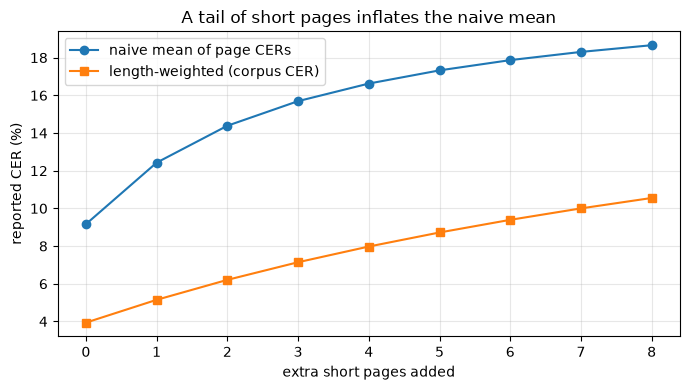

In [5]:
import matplotlib.pyplot as plt

def both(pages):
    r = [(cer(a, b), len(a)) for a, b in pages]
    return (sum(c for c, _ in r) / len(r),
            sum(c * n for c, n in r) / sum(n for _, n in r))

short = ("adjourned", "adjoumed")
xs, naive_ys, weighted_ys = [], [], []
for k in range(0, 9):
    n, w = both(PAGES + [short] * k)
    xs.append(k); naive_ys.append(n * 100); weighted_ys.append(w * 100)

plt.figure(figsize=(7, 4))
plt.plot(xs, naive_ys, "o-", label="naive mean of page CERs")
plt.plot(xs, weighted_ys, "s-", label="length-weighted (corpus CER)")
plt.xlabel("extra short pages added"); plt.ylabel("reported CER (%)")
plt.title("A tail of short pages inflates the naive mean")
plt.legend(); plt.grid(alpha=.3); plt.tight_layout(); plt.show()

## 4 · Turning a number into a work list

In [6]:
from collections import Counter
import difflib

def confusions(pairs):
    conf = Counter()
    for ref, hyp in pairs:
        sm = difflib.SequenceMatcher(a=ref, b=hyp, autojunk=False)
        for tag, i1, i2, j1, j2 in sm.get_opcodes():
            if tag != "equal":
                conf[(ref[i1:i2], hyp[j1:j2])] += 1
    return conf

CORPUS = PAGES + [
    ("the clerk was instructed to write to the surveyor",
     "the clerk was instructed to vvrite to the surveyor"),
    ("modern methods of drainage", "modem methods of drainage"),
]

conf = confusions(CORPUS)
for (r, h), n in conf.most_common():
    print(f"{r!r:>8} -> {h!r:<8} {n}")

total = sum(conf.values())
top2 = sum(n for _, n in conf.most_common(2))
print(f"\ntop 2 confusions = {top2}/{total} = {top2/total:.0%} of all edits")

     'w' -> 'vv'     2
    'rn' -> 'm'      2
     'p' -> ''       1

top 2 confusions = 4/5 = 80% of all edits


Two shape confusions cause most of the damage. Both are fixable with a rule and a
dictionary — no retraining. **Look at the confusion table before touching the
model**; the error distribution is almost always more skewed than the rate suggests.

## 5 · What the metric cannot see

In [7]:
REF_Y = "the works were completed in 1957 at a cost of 1,200 pounds"

cases = [
    ("one digit wrong",      REF_Y.replace("1957", "1857")),
    ("one comma lost",       REF_Y.replace("1,200", "1200")),
    ("fluent invention",     "the works were completed in 1957 at a cost of "
                             "1,200 pounds as agreed by the committee"),
]
for label, hyp in cases:
    print(f"{label:20} CER={cer(REF_Y,hyp):.4f}  WER={wer(REF_Y,hyp):.4f}")

one digit wrong      CER=0.0172  WER=0.0833
one comma lost       CER=0.0172  WER=0.0833
fluent invention     CER=0.4655  WER=0.4167


The wrong century and the lost comma cost the same. And the last row is the one to
worry about: a system that *invents* plausible text is penalised only in proportion
to how much it added — while a system that honestly marks a passage unreadable is
penalised just as hard.

Any evaluation that rewards this selects for confident fabrication. If your pipeline
can decline to transcribe, **report coverage alongside error rate, always.**